# 05: Report figures

Figures made only for the final report. The analysis itself is in notebooks 02–04.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().parent
FIGURES = ROOT / "reports" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

positions = pd.read_parquet(ROOT / "data" / "processed" / "positions.parquet")

## Cover figure: one game

My winning chances move by move in one recent game (white, 10 minutes), with my blunders marked.
I was winning, blundered twice, got back to winning, then blundered again, and only won because my
opponent blundered back near the end. Picked by eye as a typical example; it isn't used for
anything else.

,ply,win_before,win_after,win_loss
253321,29,68.90,47.88,21.01
253325,33,36.28,7.82,28.46
253333,41,68.90,11.51,57.39


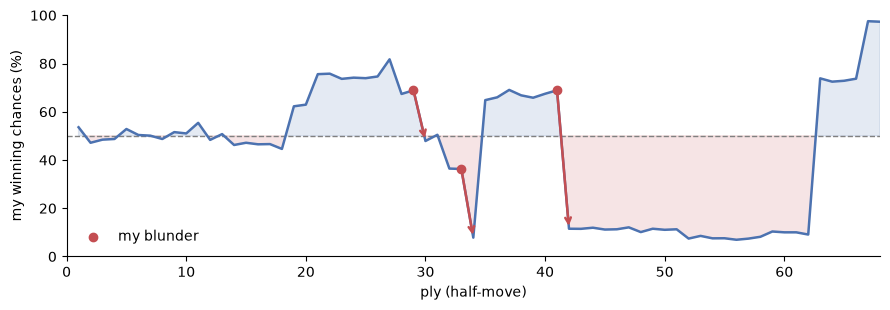

In [2]:
GAME = "3a424c6a-a561-11f1-856c-7c639201000f"

game = positions[positions.game_id == GAME].sort_values("ply")
# win_before is from the mover's side, so flip the opponent's moves to my side
mine = game.win_before.where(game.is_my_move, 100 - game.win_before)
last = game.iloc[-1]
end = last.win_after if last.is_my_move else 100 - last.win_after
ply = list(game.ply) + [last.ply + 1]
win = list(mine) + [end]

blunders = game[game.is_my_move & game.is_blunder]
after = blunders.win_after

fig, ax = plt.subplots(figsize=(9, 3.2))
ax.axhline(50, color="grey", linestyle="--", linewidth=1)
ax.fill_between(ply, win, 50, where=[w >= 50 for w in win], color="#4C72B0", alpha=0.15,
                interpolate=True)
ax.fill_between(ply, win, 50, where=[w < 50 for w in win], color="#C44E52", alpha=0.15,
                interpolate=True)
ax.plot(ply, win, color="#4C72B0", linewidth=1.8)
for (_, b), a in zip(blunders.iterrows(), after):
    ax.annotate("", xy=(b.ply + 1, a), xytext=(b.ply, b.win_before),
                arrowprops=dict(arrowstyle="->", color="#C44E52", linewidth=1.8))
ax.scatter(blunders.ply, blunders.win_before, color="#C44E52", zorder=3, label="my blunder")
ax.set_xlabel("ply (half-move)")
ax.set_ylabel("my winning chances (%)")
ax.set_ylim(0, 100)
ax.set_xlim(0, ply[-1])
ax.legend(loc="lower left", frameon=False)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(FIGURES / "05_cover_game.png", dpi=200)
blunders[["ply", "win_before", "win_after", "win_loss"]]

## Numbers quoted in the report

Notebook 02's drift table counts both players' moves. The report quotes my own moves, so they're
printed here.

In [3]:
mine = positions[positions.is_my_move]
mine.groupby(mine.end_time.dt.year).is_blunder.agg(["mean", "size"]).rename(
    columns={"mean": "my blunder rate", "size": "my moves"}).round(4)

,my blunder rate,my moves
end_time,,
2022,0.0981,4300
2023,0.0965,57069
2024,0.0936,13352
2025,0.0877,29483
2026,0.0839,25844
